### **SELECTED CANDIDATES**
- Category Repurchase
- Recency (baseline)

Metrics: HIT@12 - Recall@12
* Test user: Have history, at least one repeat purchase in the test window
* Hit: An article the user already owned and bought again
* Items: Candidates come only from owned items

Expected phenomenon:
* The candidate pool is each user’s own history, so many users have fewer than 12 items. Say how you handle short lists, and report coverage.
* Hit rates are very low, about 0.03% to 3% per pair depending on age, so the CI on the lift matters more than the point estimate.

In [1]:
import pandas as pd
import numpy as np

from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, plot_comparison, plot_bootstrap
from models.r1_recent import R1RecentModel
from models.cat_repurchase import CategoryRepurchaseModel

In [3]:
# data
train_val_raw, test_raw=load_splits(
    train_path="../data/split/train.parquet",
    val_path="../data/split/val.parquet",
    test_path="../data/split/test.parquet",
    concat_train_val=True
)

train_val = train_val_raw[train_val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]
assert train_val.t_dat.max() < test.t_dat.min()

articles=pd.read_parquet("../data/cleaned_art.parquet")
types = articles.set_index("article_id")["product_type_no"] #product type

In [4]:
# models
models={
    "r1_recent": R1RecentModel(),
    "cat_repurchase": CategoryRepurchaseModel(types, horizon_days=7)
}

In [5]:
summary, per_user = compare_models(models, train_val, test, baseline="r1_recent",
                                   problem="buy_again", k=12)

Setup: user_group=warm, truth_mode=repeat -> 743 users, 947 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating cat_repurchase ...


In [6]:
ci_df, paired_df=bootstrap_compare(per_user, baseline="r1_recent", k=12)

In [10]:
# freeze results
summary.to_csv("frozen_results/repurchase/test_summary.csv")
ci_df.to_csv("frozen_results/repurchase/ci_df_test.csv")
paired_df.to_csv("frozen_results/repurchase/paired_df_test.csv")

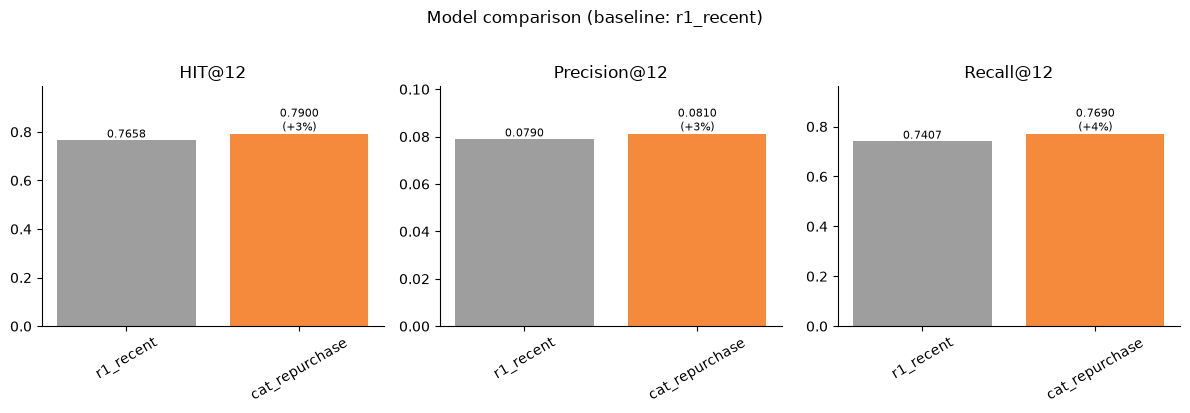

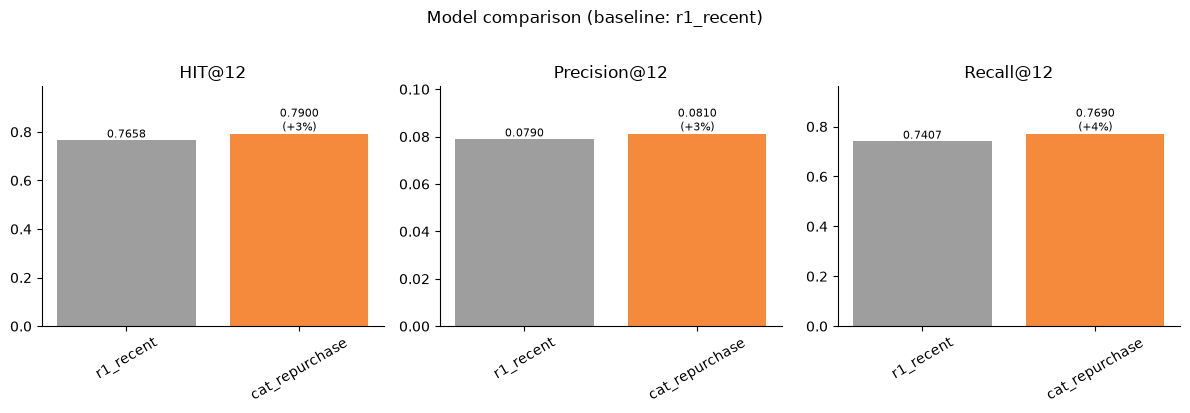

In [17]:
plot_comparison(summary, baseline="r1_recent", save_path="figures/repurchase/test_summary.png")

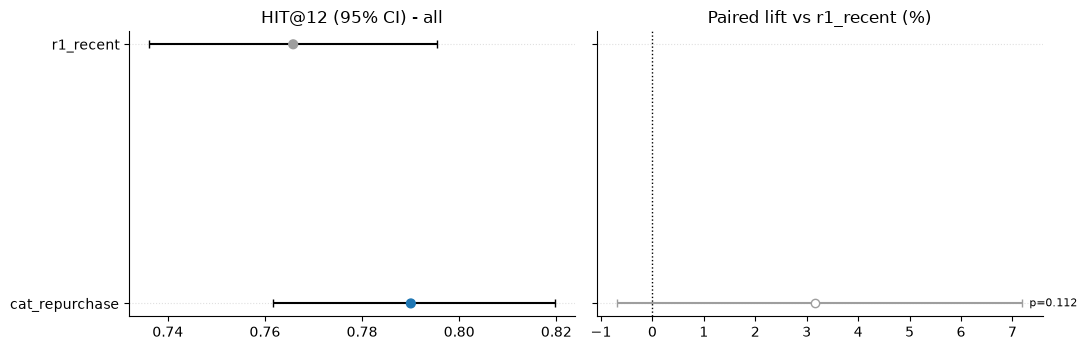

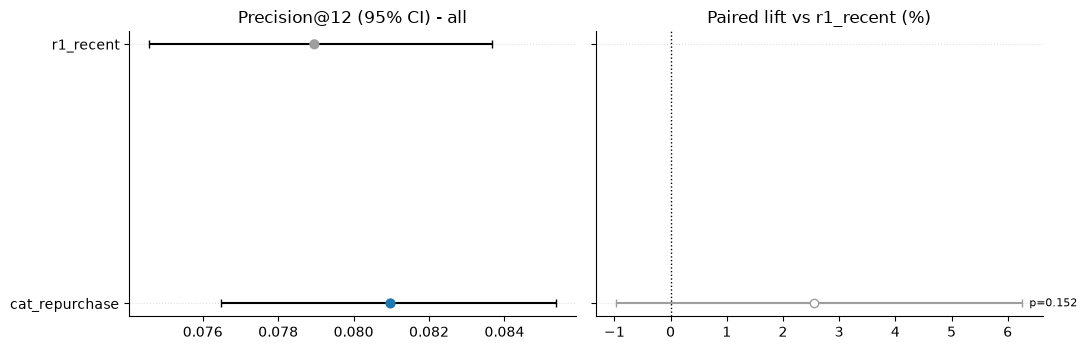

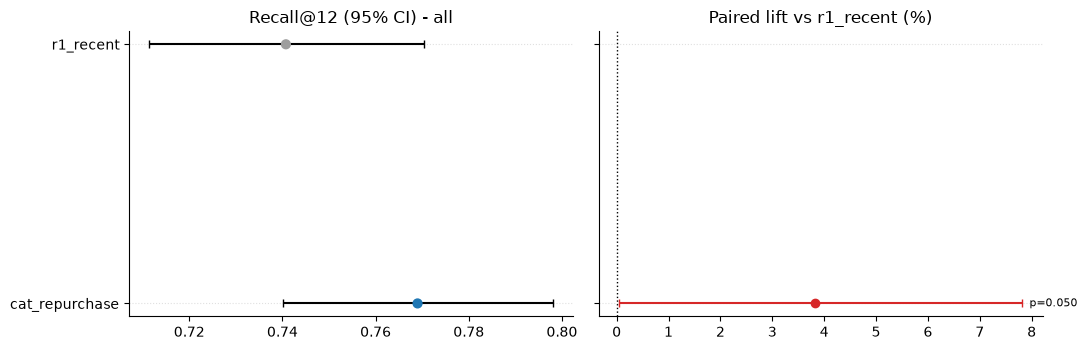

In [16]:
metrics=["HIT@12", "Precision@12", "Recall@12"]

for m in metrics:
    plot_bootstrap(ci_df, paired_df, baseline="r1_recent", metric=m, save_path=f"figures/repurchase/test_bootstrap_{m}@12.png")

### **CONCLUSION**

Not so significant → can rely on other metrics & future work as the recent is too strong

**Why validation and test can disagree**
* Selection optimism: you chose the model because it looked good on validation, so its validation lift is biased upward. Some shrinkage on test is expected -> limitation
* Low power: repeats are rare, so each CI is wide. The test CIs reach from about −1% to +7%, which is consistent with the validation lift being real but smaller than it looked.
* Different window: one test week is a single sample, and promotions or seasonality shift repeat behavior.

On validation, `category_repurchase` significantly outperformed the recency baseline. On the held-out test it showed a consistent but smaller lift **(HIT@12 +3.2%, 95% CI −0.7% to +7.2%; Recall@12 +3.8%, CI +0.04% to +7.8%)**, which is not statistically conclusive. We attribute the shrinkage to selection effects on validation and limited power with rare repeat events. We retain `category_repurchase` as the repurchase candidate because the direction is consistent, it costs nothing in complexity relative to the baseline, and the test does not contradict validation.